# 04 — Real-world validation: Indian state crop yields, 1997–2020 (RQ4)

**Question:** do the Kaggle findings — fertilizer dominates, rainfall and
pesticide matter, crop type does not, and flexible models add only a little —
hold on real government data?

**Data:** 19,689 state × crop × season × year records (Mendeley `ncw2vbcgnk`,
CC BY 4.0). The heavy lifting (cleaning, time-ordered CV, nested tuning and the
single test evaluation) is done by `python -m src.india`; this notebook audits
the data, explains every decision and reads back the saved results so the
numbers here are exactly the ones in `results/tables/`.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable when run from notebooks/

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.evaluate import holdout_metrics
from src.explain import grouped_importance, mean_abs_shap, tree_shap
from src.india import clean_india, india_xy, load_india_raw, lookup_baseline
from src.plots import save_figure

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
raw = load_india_raw()
Y, CROP, YEAR = config.INDIA_TARGET, config.INDIA_CROP, config.INDIA_YEAR

## 1. Audit (as in Phase 1)

In [2]:
text_cols = raw.select_dtypes(include=["object", "string"]).columns
audit = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "missing": raw.isna().sum(),
        "n_unique": raw.nunique(),
        "values_with_padding": [
            int((raw[c] != raw[c].str.strip()).sum()) if c in text_cols else 0 for c in raw.columns
        ],
    }
)
print("Shape:", raw.shape, "| exact duplicate rows:", int(raw.duplicated().sum()))
audit

Shape: (19689, 10) | exact duplicate rows: 0


,dtype,missing,n_unique,values_with_padding
Crop,str,0,55,172
Crop_Year,int64,0,24,0
Season,str,0,6,19689
State,str,0,30,0
Area,float64,0,13644,0
Production,int64,0,14016,0
Annual_Rainfall,float64,0,634,0
Fertilizer,float64,0,18598,0
Pesticide,float64,0,17405,0
Yield,float64,0,13551,0


In [3]:
y_raw = raw[Y]
print(
    f"Yield: min {y_raw.min():.3f}, max {y_raw.max():,.1f}, mean {y_raw.mean():.2f}, "
    f"median {y_raw.median():.3f}, std {y_raw.std():.1f}, skewness {y_raw.skew():.1f}, "
    f"values <= 0: {(y_raw <= 0).sum()}, Area <= 0: {(raw[config.INDIA_AREA] <= 0).sum()}"
)
raw.groupby(raw[CROP].str.strip())[Y].median().sort_values(ascending=False).head(8).round(2)

Yield: min 0.000, max 21,105.0, mean 79.95, median 1.030, std 878.3, skewness 12.8, values <= 0: 112, Area <= 0: 0


Crop
Coconut         8466.32
Sugarcane         53.16
Banana            17.95
Tapioca           11.12
Potato            10.18
Onion              9.19
Sweet potato       8.51
Jute               8.15
Name: Yield, dtype: float64

**Interpretation.** No missing values and no duplicates. Two text problems:
every `Season` value is padded with trailing spaces (e.g. `"Kharif     "`) and
172 `Crop` values are too, so all text is stripped. The target is extremely
skewed (skewness ≈ 13) because 55 crops have very different yield scales, and
**Coconut's median "yield" is ≈ 8,500** — Indian statistics report coconut in
*nuts* per hectare, not tonnes, so it is excluded rather than mixed into a t/ha
model. 112 rows have zero yield.

## 2. Leakage and scale checks

### 2a. Production is the target in disguise

In [4]:
ratio = raw[config.INDIA_PRODUCTION] / raw[config.INDIA_AREA]
kept_crops = ~raw[CROP].str.strip().isin(config.INDIA_EXCLUDED_CROPS)
print(f"corr(Production / Area, Yield), excluded crops removed = {ratio[kept_crops].corr(y_raw[kept_crops]):.3f}")

corr(Production / Area, Yield), excluded crops removed = 0.953


**Interpretation.** Production / Area correlates ≈ 0.95 with Yield (Coconut
excluded): a model given Production and Area would learn division, not
agronomy. **Production is dropped** before anything else.

### 2b. What are the Fertilizer and Pesticide columns really?

share of fert_per_ha variance explained by year alone: 1.0000
share of pest_per_ha variance explained by year alone: 1.0000
corr(Fertilizer total, Area) = 0.973


fert_per_ha         pest_per_ha      
                  min     max         min   max
Crop_Year                                      
1997            95.17   95.17        0.31  0.31
1998            98.80   98.80        0.29  0.29
1999           106.13  106.13        0.27  0.27
2000            98.17   98.17        0.26  0.26
2001           102.13  102.13        0.26  0.26
2002            94.67   94.67        0.25  0.25

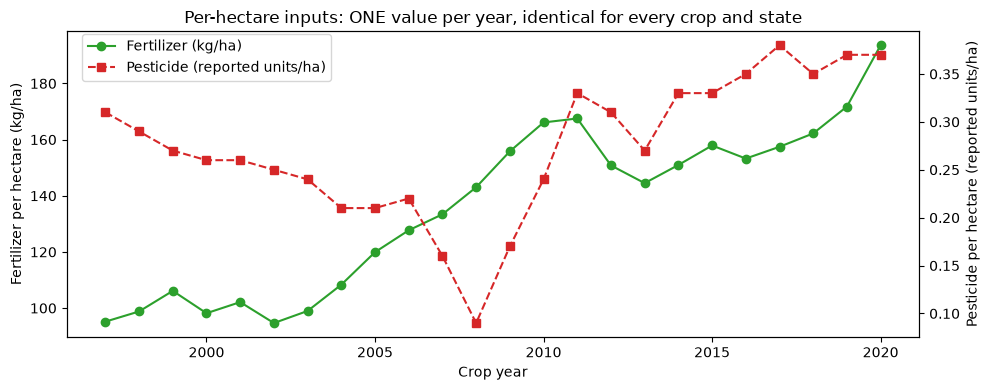

In [5]:
per_ha = raw.assign(
    fert_per_ha=raw[config.INDIA_FERTILIZER] / raw[config.INDIA_AREA],
    pest_per_ha=raw[config.INDIA_PESTICIDE] / raw[config.INDIA_AREA],
)
by_year = per_ha.groupby(YEAR)[["fert_per_ha", "pest_per_ha"]].agg(["min", "max"])
for col in ("fert_per_ha", "pest_per_ha"):
    share = per_ha.groupby(YEAR)[col].transform("mean").var() / per_ha[col].var()
    print(f"share of {col} variance explained by year alone: {share:.4f}")
print(f"corr(Fertilizer total, Area) = {raw[config.INDIA_FERTILIZER].corr(raw[config.INDIA_AREA]):.3f}")

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(by_year.index, by_year[("fert_per_ha", "max")], "o-", color="tab:green", label="Fertilizer (kg/ha)")
ax1.set(xlabel="Crop year", ylabel="Fertilizer per hectare (kg/ha)")
ax2 = ax1.twinx()
ax2.plot(by_year.index, by_year[("pest_per_ha", "max")], "s--", color="tab:red", label="Pesticide (reported units/ha)")
ax2.set_ylabel("Pesticide per hectare (reported units/ha)")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
ax1.set_title("Per-hectare inputs: ONE value per year, identical for every crop and state")
save_figure(fig, "india_inputs_per_ha_by_year")
by_year.round(2).head(6)

**Interpretation — a key limitation for RQ4.** After dividing by Area (the
mandatory scale fix), fertilizer and pesticide per hectare have **exactly one
value per year** — min = max in every year, and year explains 100 % of their
variance. The raw columns were evidently *constructed* as Area × a national
per-hectare figure for that year. So in this dataset:

* the per-hectare inputs carry **no information about crop, state or farm** —
  they are just a national time trend (fertilizer rose from ≈ 95 to ≈ 194 kg/ha);
* the raw totals only look informative because they are proportional to Area
  (r ≈ 0.97);
* **the India data cannot test the Kaggle claim that fertilizer drives yield.**
  It can only test whether the *national fertilizer trend* tracks yields over
  time.

The per-hectare columns are kept (as specified). `Crop_Year` itself is used
only for splitting and is never passed to a model. **But because each
per-hectare value belongs to exactly one year, the models still "see" the year
implicitly through `Fertilizer_per_ha`.** That is legitimate, because the year
is known when a prediction is made, so it is not leakage. It does mean
(a) any year-level shock is attributed to "fertilizer", and (b) tree models
cannot extrapolate to 2019–2020, whose index values exceed the training
maximum.

## 3. Cleaning

In [6]:
clean, removed = clean_india(raw)
pd.Series(removed, name="rows")

rows_raw              19689
area_or_yield_le_0      112
excluded_crops          165
exact_duplicates          0
rows_clean            19412
Name: rows, dtype: int64

**Interpretation.** 112 rows with zero yield and 165 Coconut rows are removed
(0 rows had Area ≤ 0, 0 duplicates), leaving 19,412 rows. Area is kept only as
`log1p(Area)`: raw area spans 0.5 to 5 × 10⁷ ha, and the log keeps huge states
from dominating while still letting the model use "how established is this crop
here".

## 4. Target transform

skewness after cleaning: raw = 21.52, log1p = 1.95


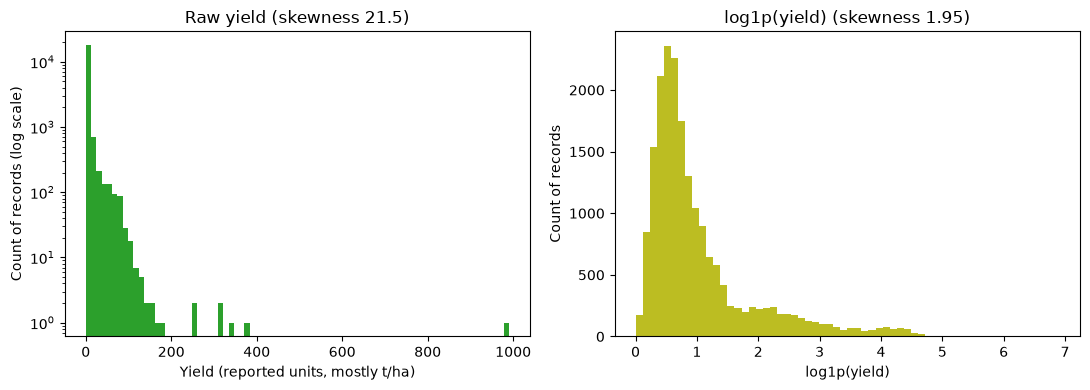

In [7]:
skew_raw, skew_log = clean[Y].skew(), np.log1p(clean[Y]).skew()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(clean[Y], bins=80, color="tab:green")
axes[0].set(yscale="log", xlabel="Yield (reported units, mostly t/ha)", ylabel="Count of records (log scale)", title=f"Raw yield (skewness {skew_raw:.1f})")
axes[1].hist(np.log1p(clean[Y]), bins=60, color="tab:olive")
axes[1].set(xlabel="log1p(yield)", ylabel="Count of records", title=f"log1p(yield) (skewness {skew_log:.2f})")
save_figure(fig, "india_target_distribution")
print(f"skewness after cleaning: raw = {skew_raw:.2f}, log1p = {skew_log:.2f}")

**Interpretation.** After cleaning, raw yield skewness is ≈ 22, far above the
rule-of-thumb threshold of 1. It is even higher than before cleaning, because
removing Coconut leaves sugarcane's long tail as the extreme. Sugarcane and
banana yield tens of t/ha while pulses yield under 1 t/ha. log1p reduces the
skewness to ≈ 2 (printed above). **Every model is trained on log1p(yield)
and its predictions are transformed back**, so all metrics below are in the
original units.

## 5. Physically implausible yields in the source data

In [8]:
IMPLAUSIBLE_FACTOR = 10  # flag values > 10 x the crop's 99th percentile
median = clean.groupby(CROP)[Y].transform("median")
suspect = clean[clean[Y] > IMPLAUSIBLE_FACTOR * median].assign(crop_median=median)
print(f"{len(suspect)} records exceed {IMPLAUSIBLE_FACTOR} x their crop's median yield")
suspect.sort_values(Y, ascending=False)[[CROP, config.INDIA_STATE, YEAR, Y, "crop_median"]].head(12).round(2)

82 records exceed 10 x their crop's median yield


,Crop,State,Crop_Year,Yield,crop_median
6070,Maize,Maharashtra,1997,989.87,1.96
4949,Onion,Andhra Pradesh,2017,381.42,9.47
2641,Cashewnut,Tamil Nadu,2008,338.55,0.46
17638,Potato,Delhi,2010,311.02,10.18
17647,Potato,Delhi,2011,311.00,10.18
17593,Potato,Delhi,2009,249.99,10.18
5284,Onion,Andhra Pradesh,2018,247.57,9.47
10448,Onion,Haryana,2008,178.65,9.47
6066,Cotton(lint),Maharashtra,1997,95.99,1.44
10788,Bajra,Chhattisgarh,2009,74.30,1.04


**Interpretation.** 82 records (0.4 %) exceed 10× their crop's median yield,
and many are physically impossible: maize at 990 t/ha (Maharashtra 1997),
onion at 381 t/ha, cashew nut at 339 t/ha, potato at 311 t/ha (Delhi), and
bajra, sesamum and arhar at 68–74 t/ha when their typical yield is ≈ 0.5–1
t/ha. These are data-entry or unit errors in the source. They are **not removed** (removing test rows after seeing errors would
be tuning to the test set), but they inflate RMSE, so per-crop results below
also report the median absolute error, which ignores a few wild values.

## 6. Time-based split

In [9]:
train = pd.read_parquet(config.INDIA_TRAIN_PARQUET)
test = pd.read_parquet(config.INDIA_TEST_PARQUET)
print(f"train: {train[YEAR].min()}-{train[YEAR].max()}, {len(train):,} rows | test: {test[YEAR].min()}-{test[YEAR].max()}, {len(test):,} rows")
assert train[YEAR].max() < test[YEAR].min()
for col in config.INDIA_CATEGORICAL_FEATURES:
    unseen = ~test[col].isin(train[col])
    print(f"test rows whose {col} never appears in training: {unseen.sum()} {sorted(test.loc[unseen, col].unique())}")
fert = config.INDIA_FERTILIZER_PER_HA
print(f"{fert}: train max {train[fert].max():.1f}, test range {test[fert].min():.1f}-{test[fert].max():.1f}")

train: 1997-2015, 15,186 rows | test: 2016-2020, 4,226 rows
test rows whose Crop never appears in training: 10 ['Other Summer Pulses']
test rows whose Season never appears in training: 0 []


test rows whose State never appears in training: 0 []
Fertilizer_per_ha: train max 167.5, test range 153.2-193.6


**Interpretation.** Training uses 1997–2015 and testing 2016–2020, so the model
never sees the future — a random split would let it learn, say, 2018 state
conditions from other 2018 rows. Cross-validation inside the training years is
also time-ordered (`YearBlockSplit`: `TimeSeriesSplit` over whole years, used
for both the outer CV and the inner hyperparameter search). Two real-world
difficulties appear. 10 test rows belong to a crop never seen in training
("Other Summer Pulses"); it is encoded as "unknown" (an all-zero one-hot row).
There are no unseen states or seasons. Also, the fertilizer index for 2019–2020
(up to 193.6 kg/ha) lies above the training maximum (167.5), which tree models
cannot extrapolate beyond.

## 7. Model comparison (time-ordered CV and the single 2016–2020 test)

In [10]:
cv = pd.read_csv(config.TABLES_DIR / "india_cv.csv")
cv[["model", "rmse_mean", "rmse_std", "mae_mean", "r2_mean", "r2_std"]].round(3)

,model,rmse_mean,rmse_std,mae_mean,r2_mean,r2_std
0,random_forest,5.885,2.962,1.258,0.769,0.166
1,gradient_boost,6.013,2.917,1.254,0.761,0.165
2,polynomial,7.916,2.397,2.145,0.606,0.140
3,multiple_lr,8.072,2.321,2.029,0.592,0.134
4,ridge,8.106,2.298,2.038,0.588,0.131
5,lasso,8.133,2.301,2.047,0.586,0.132
6,polynomial_deg3,9.860,3.160,2.946,0.370,0.269
7,simple_lr,12.811,1.559,3.873,-0.044,0.009
8,dummy_mean,12.828,1.560,3.842,-0.047,0.009


In [11]:
test_results = pd.read_csv(config.TABLES_DIR / "india_test.csv")
test_results.round(3)

,model,rmse,mae,r2
0,random_forest,8.119,1.580,0.650
1,gradient_boost,8.136,1.400,0.648
2,polynomial,9.481,2.180,0.523
3,multiple_lr,9.508,2.190,0.520
4,ridge,9.517,2.192,0.519
5,lasso,9.550,2.201,0.516
6,polynomial_deg3,9.837,2.322,0.486
7,simple_lr,14.014,4.114,-0.043
8,dummy_mean,14.039,4.080,-0.047


## 8. Reference: how far does knowing *only* the crop (and state) get you?

A model is only useful if it beats simple look-ups. These baselines predict
each test row with the training-years (1997–2015) average log-yield of its crop,
or of its crop in its state — no features, no learning beyond an average.

In [12]:
names = json.loads((config.MODELS_DIR / "india_model_names.json").read_text())
best = joblib.load(config.MODELS_DIR / "india_best_overall.joblib")
X_test, y_test = india_xy(test)
best_pred = best.predict(X_test)
reference = pd.DataFrame(
    [
        {"predictor": "crop lookup (training mean per crop)", **holdout_metrics(y_test, lookup_baseline(train, test, [CROP]))},
        {"predictor": "crop x state lookup", **holdout_metrics(y_test, lookup_baseline(train, test, [CROP, config.INDIA_STATE]))},
        {"predictor": f"best model ({names['best_overall']})", **holdout_metrics(y_test, best_pred)},
    ]
)
reference.to_csv(config.TABLES_DIR / "india_reference_baselines.csv", index=False)
reference.round(3)

,predictor,rmse,mae,r2
0,crop lookup (training mean per crop),10.269,2.503,0.440
1,crop x state lookup,7.808,1.387,0.676
2,best model (random_forest),8.119,1.580,0.650


**Interpretation (sections 7–8).**

* **Model ranking reverses relative to Kaggle.** Tree models (random forest,
  XGBoost) are clearly best — test RMSE ≈ 8.1 vs ≈ 9.5 for the linear family and
  14.0 for the dummy — whereas on Kaggle the polynomial tied with XGBoost and
  random forest was worst. Degree-3 polynomial is *worse* than degree 2 (more
  terms, more over-fitting), and `simple_lr` on `Fertilizer_per_ha` is no better
  than the dummy: the national fertilizer trend explains nothing.
* **But a crop × state look-up table beats every model** (section 8). The
  pooled R² of ≈ 0.65 mostly comes from knowing *which crop in which state* a
  record is — crops differ in yield by two orders of magnitude — not from
  rainfall, fertilizer or pesticide. Trees win over linear models because they
  can encode crop × state combinations (an interaction); a linear model on
  one-hot crop + one-hot state cannot.
* CV standard deviations are large (RMSE ± ≈ 3): some year blocks contain a
  few extreme records (section 5) that dominate the squared error.

## 8b. Ablation: do the per-hectare inputs (a disguised year) matter?

`Fertilizer_per_ha` and `Pesticide_per_ha` hold one national value per year
(section 2b), so they are effectively the year. To measure what they contribute,
`python -m src.india` re-runs the **identical** model suite, with the same
1997–2015 / 2016–2020 split, seeds and time-ordered tuning, but **without these
two columns**. The results are only compared; no model was chosen or changed
because of them.

In [13]:
ablation = pd.read_csv(config.TABLES_DIR / "india_ablation.csv")
print("delta_rmse = RMSE without - RMSE with  (> 0: the columns help, < 0: they hurt)")
ablation.round(4)

delta_rmse = RMSE without - RMSE with  (> 0: the columns help, < 0: they hurt)


,model,rmse_with,r2_with,rmse_without,r2_without,delta_rmse,delta_r2
0,random_forest,8.1195,0.6499,8.1352,0.6485,0.0157,-0.0014
1,gradient_boost,8.1358,0.6485,8.1545,0.6469,0.0187,-0.0016
2,polynomial,9.4807,0.5227,9.7929,0.4907,0.3122,-0.0320
3,multiple_lr,9.5082,0.5199,9.7829,0.4918,0.2747,-0.0281
4,ridge,9.5169,0.5190,9.7921,0.4908,0.2752,-0.0282
5,lasso,9.5497,0.5157,9.8247,0.4874,0.2750,-0.0283
6,polynomial_deg3,9.8373,0.4861,9.7906,0.4910,-0.0467,0.0049
7,simple_lr,14.0139,-0.0429,14.0356,-0.0462,0.0217,-0.0032
8,dummy_mean,14.0391,-0.0467,14.0391,-0.0467,0.0000,0.0000


In [14]:
ranges = pd.read_csv(config.TABLES_DIR / "india_feature_ranges.csv")
ranges.round(3)

,feature,train_min,train_max,test_min,test_max,share_test_rows_above_train_max,share_test_rows_below_train_min
0,Fertilizer_per_ha,94.67,167.52,153.25,193.61,0.259,0.0
1,Pesticide_per_ha,0.09,0.33,0.35,0.38,1.000,0.0


**Interpretation — the effect depends on the model family.**

* **Linear family: the columns help modestly.** Without them, test RMSE rises
  by ≈ 0.27–0.31 (≈ 3 %) for polynomial, OLS, ridge and lasso, and R² falls by
  ≈ 0.03. On the log scale a linear model can *extrapolate* a rising index,
  so the columns work as a **time trend** (national fertilizer use and yields
  both rose). They cannot tell a fertilizer effect from any other trend, such
  as better seeds or irrigation, because they are collinear with the year.
* **Tree models: they do essentially nothing.** RMSE changes by only
  +0.016 (random forest) and +0.019 (XGBoost), about 0.2 %. The range table
  shows why. **100 % of test rows have `Pesticide_per_ha` above its training
  maximum** (0.35–0.38 vs ≤ 0.33), and **26 % have `Fertilizer_per_ha` above
  it** (the 2019–2020 values of 171.8 and 193.6 vs ≤ 167.5). Trees cannot
  extrapolate, so every test row falls into the last split, as if it came from
  the latest training years.
* **Degree-3 polynomial: they hurt** (RMSE 0.05 *lower* without them). The
  cubic terms of an extrapolated index over-fit.
* `simple_lr` switches to `log_Area` and stays ≈ dummy, and `dummy_mean` is
  unchanged (as it must be).

**Conclusion.** The best model (random forest, 8.12 → 8.14), the ranking
(trees ≫ linear) and the finding that a crop × state look-up (7.81) beats
every model all hold **with or without** these columns. The year-index
columns explain none of the headline results. Their only contribution is a
small extrapolated time trend for the linear models.

## 9. Per-crop test error for the 10 most common crops

,crop,n_test_rows,mean_yield,rmse,relative_rmse,r2,median_abs_error
0,Rice,246,2.548,0.689,0.270,0.116,0.460
1,Maize,205,2.875,3.090,1.075,-3.145,0.481
2,Urad,170,0.716,0.286,0.399,-0.076,0.166
3,Moong(Green Gram),165,0.640,0.266,0.416,-0.204,0.189
4,Groundnut,157,1.731,1.170,0.676,-1.665,0.691
5,Sesamum,152,0.759,2.606,3.435,-0.001,0.240
6,Potato,142,12.540,5.155,0.411,0.426,1.824
7,Bajra,111,2.034,3.351,1.648,-0.002,0.532
8,Arhar/Tur,110,0.972,0.416,0.428,-0.230,0.257
9,Ragi,106,1.364,1.001,0.734,-0.484,0.390


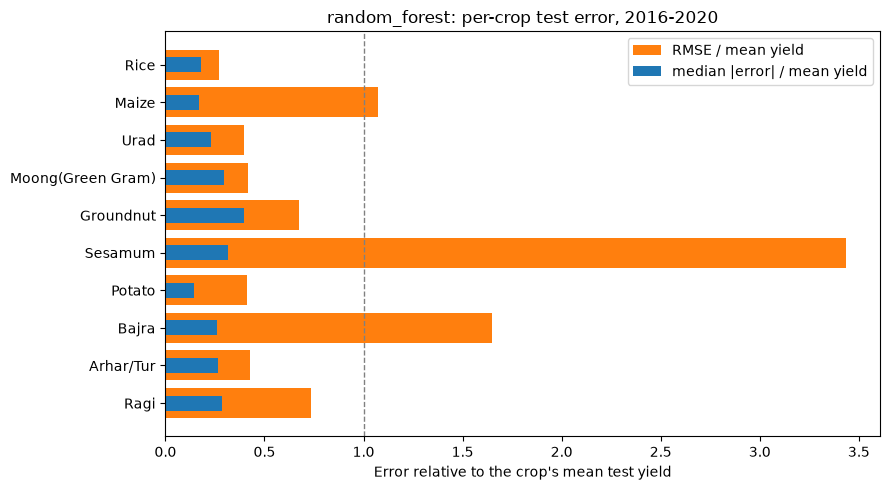

In [15]:
per_crop = pd.read_csv(config.TABLES_DIR / "india_per_crop_rmse.csv")
fig, ax = plt.subplots(figsize=(9, 5))
pc = per_crop.iloc[::-1]
ax.barh(pc["crop"], pc["relative_rmse"], color="tab:orange", label="RMSE / mean yield")
ax.barh(pc["crop"], pc["median_abs_error"] / pc["mean_yield"], color="tab:blue", height=0.4, label="median |error| / mean yield")
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set(xlabel="Error relative to the crop's mean test yield", title=f"{names['best_overall']}: per-crop test error, 2016-2020")
ax.legend()
save_figure(fig, "india_per_crop_error")
per_crop.round(3)

**Interpretation.** One global RMSE (≈ 8.1) hides very different stories.

* **Global RMSE is dominated by high-yield crops.** Potato alone has
  RMSE ≈ 5.2 t/ha on a mean of 12.5 t/ha. Sugarcane and banana, which are not
  in the top 10, weigh even more. For pulses such as urad and moong the typical
  error is ≈ 0.2 t/ha.
* **Relative to each crop's own yield**, the median error is 15–40 % of the
  mean (blue bars). RMSE is much larger for maize, sesamum and bajra (orange
  bars above 1) because a handful of impossible test records (section 5)
  dominate their squared error.
* **Within a crop, the model explains little.** Per-crop R² is 0.43 for potato
  and 0.12 for rice, and **negative for the other 8 crops**. For those, the
  model does worse than predicting each crop's own 2016–2020 average. It
  captures *between*-crop and *between*-state differences, not year-to-year or
  within-crop variation. That is expected: the only time-varying features are
  state-level annual rainfall and a national fertilizer/pesticide index.

## 10. SHAP for the best model

SHAP computed on 300 test rows (values are in log1p-yield units)


Crop                 0.834
State                0.055
log_Area             0.049
Annual_Rainfall      0.040
Fertilizer_per_ha    0.009
Season               0.009
Pesticide_per_ha     0.005
Name: share, dtype: float64

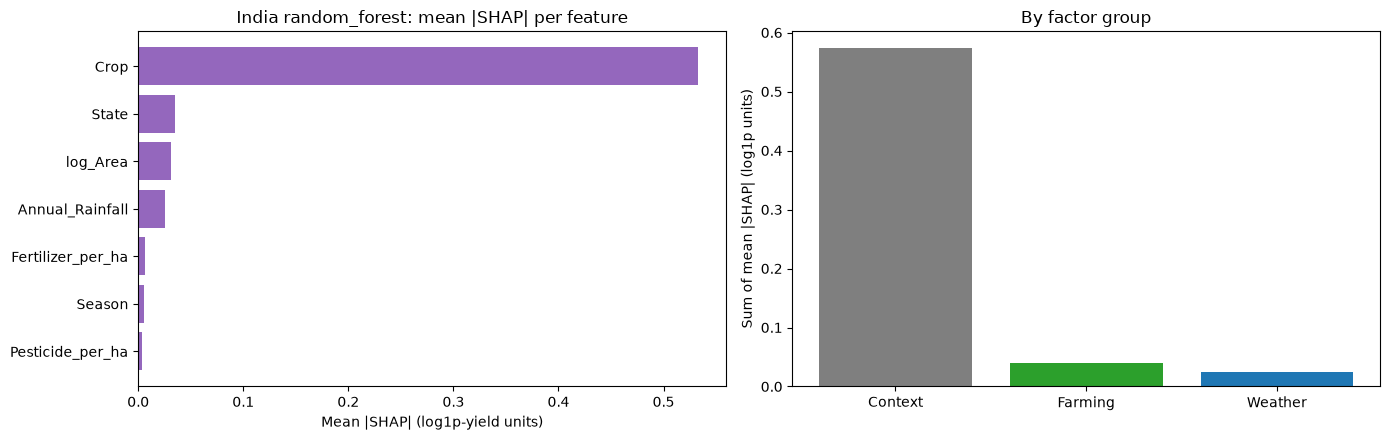

In [16]:
# TreeExplainer on 500+ deep random-forest trees is single-threaded and took over
# 10 minutes for 2,000 rows, so a 300-row random sample of the test years is used;
# that is enough for a stable ranking of mean |SHAP|.
INDIA_SHAP_SAMPLE = 300
shap_inputs, model_inputs, shap_by_feature = tree_shap(
    best, X_test, config.INDIA_FEATURES, sample_size=INDIA_SHAP_SAMPLE
)
india_shap = mean_abs_shap(shap_by_feature)
india_groups = grouped_importance(india_shap, config.INDIA_FEATURE_GROUPS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
s = india_shap.iloc[::-1]
axes[0].barh(s.index, s.to_numpy(), color="tab:purple")
axes[0].set(xlabel="Mean |SHAP| (log1p-yield units)", title=f"India {names['best_overall']}: mean |SHAP| per feature")
axes[1].bar(india_groups.index, india_groups.to_numpy(), color=["tab:grey", "tab:green", "tab:blue"][: len(india_groups)])
axes[1].set(ylabel="Sum of mean |SHAP| (log1p units)", title="By factor group")
save_figure(fig, "india_shap_importance")
print(f"SHAP computed on {len(shap_by_feature)} test rows (values are in log1p-yield units)")
# Saved so the app can show the shares without recomputing SHAP (~70 s) at start-up.
pd.DataFrame({"mean_abs_shap": india_shap, "share": india_shap / india_shap.sum()}).to_csv(
    config.TABLES_DIR / "india_shap_shares.csv", index_label="feature"
)
(india_shap / india_shap.sum()).round(3).rename("share")

**Interpretation.** SHAP here is in log1p-yield units (the model's scale), so
the *shares* are the meaningful comparison:

* **Crop type alone accounts for ≈ 83 % of the mean |SHAP|**, and with state
  (≈ 6 %) and season (≈ 1 %) context makes up ≈ 90 %. The model is essentially
  a very good look-up table of crop × state yield levels, which is why the
  simple crop × state baseline in section 8 matches it.
* `log_Area` (≈ 5 %) is the most useful numeric feature. Larger planted areas
  go with established, higher-yielding crop–state combinations.
* `Annual_Rainfall` contributes ≈ 4 %. Weather matters a little at state
  level.
* **`Fertilizer_per_ha` (≈ 0.9 %) and `Pesticide_per_ha` (≈ 0.5 %) are almost
  ignored.** That is consistent with section 2b: they are a single national
  number per year and cannot explain differences between crops or states.

## 11. Do the Kaggle findings transfer?

In [17]:
kaggle_test = pd.read_csv(config.TABLES_DIR / "test_results.csv").set_index("model")
india_test = test_results.set_index("model")
comparison = pd.DataFrame(
    {
        "kaggle_test_rmse": kaggle_test["rmse"],
        "kaggle_rank": kaggle_test["rmse"].rank().astype(int),
        "india_test_rmse": india_test["rmse"],
        "india_rank": india_test["rmse"].rank().astype(int),
    }
).sort_values("india_rank")
comparison.round(3)

,kaggle_test_rmse,kaggle_rank,india_test_rmse,india_rank
model,,,,
random_forest,0.663,6.0,8.119,1
gradient_boost,0.646,1.0,8.136,2
polynomial,0.646,2.0,9.481,3
multiple_lr,0.653,5.0,9.508,4
ridge,0.653,4.0,9.517,5
lasso,0.653,3.0,9.550,6
polynomial_deg3,NaN,NaN,9.837,7
simple_lr,0.773,7.0,14.014,8
dummy_mean,1.160,8.0,14.039,9


**Interpretation — RQ4: the Kaggle conclusions largely do *not* transfer.**

| Finding on Kaggle (synthetic) | On India (real, 2016–2020 test) |
|---|---|
| Fertilizer dominates (≈ 64 % farming share, rank 1 under all 4 methods) | Fertilizer ≈ 1 % of SHAP; `simple_lr` on fertilizer = dummy. **But** the India fertilizer column is a national yearly index, so this is *untestable*, not refuted |
| Crop type, region and season irrelevant (≈ 2 %) | **Crop type is everything** (≈ 83 %); crop + state + season ≈ 90 % |
| Rainfall is second-tier (≈ 17 % weather share) | Rainfall is a small (≈ 4 %) but real contributor |
| Linear ≈ polynomial ≈ trees (gain ≈ 0.007 t/ha); RF worst | **Trees clearly best** (RMSE 8.1 vs 9.5 linear); RF best, XGBoost a close 2nd |
| Degree-2 polynomial helps a little | Degree 2 helps a little; degree 3 over-fits (worse than linear) |
| Model skill is genuine (R² ≈ 0.69 from features) | Pooled R² ≈ 0.65 comes from crop/state identity; a crop × state look-up is as good (RMSE 7.81 vs 8.12) |

**Most likely explanations:**

1. **Synthetic data.** The Kaggle generator gives every crop the same yield
   level and draws features independently. Real crops differ in yield by
   100×, so crop identity dominates any real model.
2. **Missing and coarse variables in the India data.** There is no soil
   information at all, rainfall is one annual number per state, and fertilizer
   and pesticide are national yearly averages. The field-level inputs that
   drive the Kaggle target simply do not exist here.
3. **Crop mix and interactions.** Real yield depends on crop × state
   combinations (an interaction). Trees can represent that and one-hot linear
   models cannot, which is why the model ranking flips.
4. **Data quality.** A small number of impossible yields inflate RMSE and CV
   variance.

**What does transfer:** the *methodology*. Honest splits (random for i.i.d.
data, time-based for panel data), leakage checks (Production), per-crop
evaluation, and comparing models against simple baselines all proved essential.
The comparison with baselines is exactly what exposed that the India models
learn crop/state levels rather than agronomy.